In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

shipments = pd.read_csv("shipments.csv")
routes = pd.read_csv("routes.csv")
carriers = pd.read_csv("carriers.csv")
events = pd.read_csv("events.csv")
weather = pd.read_csv("weather.csv")

print("All datasets loaded successfully!")


All datasets loaded successfully!


In [ ]:

datasets = {
    "Shipments": shipments,
    "Routes": routes,
    "Carriers": carriers,
    "Events": events,
    "Weather": weather
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Rows and columns:", df.shape)
    display(df.head())



Shipments
Rows and columns: (1208, 10)


,shipment_id,origin,destination,route_id,carrier,shipment_type,dispatch_datetime,promised_delivery_date,actual_delivery_date,service_level
0,SHP00001,Mumbai,Jaipur,R001,TrackFast,Industrial,2026-01-17 21:00:00,2026-01-20 14:48:00.000000000,2026-01-20 16:03:32.915275509,Economy
1,SHP00002,Coimbatore,Ahmedabad,R011,TrackFast,Apparel,2026-05-20 11:00:00,2026-05-22 17:01:50.769230768,2026-05-22 07:41:23.005139521,Standard
2,SHP00003,Chennai,Delhi,R014,SwiftShip,Electronics,2026-04-28 23:00:00,2026-05-01 01:28:36.923076922,2026-04-30 14:27:15.047674362,Standard
3,SHP00004,Mumbai,Kolkata,R010,TrackFast,Food,2026-03-20 18:00:00,2026-03-23 15:12:55.384615386,2026-03-23 12:43:34.281017580,Standard
4,SHP00005,Pune,Ahmedabad,R007,TrackFast,Documents,2026-03-19 15:00:00,2026-03-23 05:31:23.076923077,2026-03-23 02:13:01.701704866,Standard



Routes
Rows and columns: (18, 4)


,route_id,distance_km,route_type,number_of_hubs
0,R001,1209,Mixed,2
1,R002,1547,Highway,4
2,R003,680,Mixed,3
3,R004,562,Highway,4
4,R005,1430,Highway,1



Carriers
Rows and columns: (4, 3)


,carrier,service_level,carrier_region
0,SwiftShip,Standard,South
1,BlueDart,Express,National
2,TrackFast,Economy,West
3,GlobalMove,Standard,National



Events
Rows and columns: (2439, 5)


,shipment_id,hub_id,hub_arrival_datetime,hub_departure_datetime,exception_code
0,SHP00001,HUB07,2026-01-18 13:45:53.228818875,2026-01-18 15:45:53.228818875,NONE
1,SHP00001,HUB03,2026-01-19 06:31:46.457637754,2026-01-19 12:31:46.457637754,NONE
2,SHP00001,HUB03,2026-01-19 23:17:39.686456630,2026-01-20 02:17:39.686456630,NONE
3,SHP00002,HUB06,2026-05-21 01:53:47.668379841,2026-05-21 05:53:47.668379841,NONE
4,SHP00002,HUB07,2026-05-21 16:47:35.336759683,2026-05-21 20:47:35.336759683,NONE



Weather
Rows and columns: (1200, 4)


,shipment_id,rain_mm,visibility_km,storm_flag
0,SHP00001,2.3,6.9,0
1,SHP00002,9.5,7.9,0
2,SHP00003,6.2,9.4,0
3,SHP00004,11.6,6.5,0
4,SHP00005,0.5,9.4,0


In [ ]:

for name, df in datasets.items():
    print(f"\n===== {name} =====")
    print(df.info())



===== Shipments =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1208 entries, 0 to 1207
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   shipment_id             1208 non-null   object
 1   origin                  1208 non-null   object
 2   destination             1208 non-null   object
 3   route_id                1208 non-null   object
 4   carrier                 1208 non-null   object
 5   shipment_type           1208 non-null   object
 6   dispatch_datetime       1208 non-null   object
 7   promised_delivery_date  1208 non-null   object
 8   actual_delivery_date    1188 non-null   object
 9   service_level           1208 non-null   object
dtypes: object(10)
memory usage: 94.5+ KB
None

===== Routes =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          ------------

In [ ]:
for name , df in datasets.items():
  print(f"\n====={name}=====")
  print(df.isnull().sum())


=====Shipments=====
shipment_id                0
origin                     0
destination                0
route_id                   0
carrier                    0
shipment_type              0
dispatch_datetime          0
promised_delivery_date     0
actual_delivery_date      20
service_level              0
dtype: int64

=====Routes=====
route_id          0
distance_km       0
route_type        0
number_of_hubs    0
dtype: int64

=====Carriers=====
carrier           0
service_level     0
carrier_region    0
dtype: int64

=====Events=====
shipment_id                0
hub_id                     0
hub_arrival_datetime       0
hub_departure_datetime     0
exception_code            18
dtype: int64

=====Weather=====
shipment_id      0
rain_mm          0
visibility_km    0
storm_flag       0
dtype: int64


In [ ]:
for name, df in datasets.items():
    print(f"\n{name}")
    print("Duplicate rows:", df.duplicated().sum())

print(
    "\nDuplicate shipment IDs:",
    shipments["shipment_id"].duplicated().sum()
)


Shipments
Duplicate rows: 8

Routes
Duplicate rows: 0

Carriers
Duplicate rows: 0

Events
Duplicate rows: 0

Weather
Duplicate rows: 0

Duplicate shipment IDs: 8


In [ ]:

date_cols = [
    "dispatch_datetime",
    "promised_delivery_date",
    "actual_delivery_date"
]

for col in date_cols:
    shipments[col] = pd.to_datetime(
        shipments[col],
        errors="coerce"
    )

events["hub_arrival_datetime"] = pd.to_datetime(
    events["hub_arrival_datetime"],
    errors="coerce"
)

events["hub_departure_datetime"] = pd.to_datetime(
    events["hub_departure_datetime"],
    errors="coerce"
)

print(shipments[date_cols].dtypes)
print("\nDate conversion completed!")


dispatch_datetime         datetime64[ns]
promised_delivery_date    datetime64[ns]
actual_delivery_date      datetime64[ns]
dtype: object

Date conversion completed!


In [ ]:
shipments["route_id"] = (
    shipments["route_id"]
    .astype("string")
    .str.strip()
    .str.upper()
)

routes["route_id"] = (
    routes["route_id"]
    .astype("string")
    .str.strip()
    .str.upper()
)

print("Shipment route IDs:")
print(shipments["route_id"].head(10).tolist())

print("\nRoute standardization completed!")

Shipment route IDs:
['R001', 'R011', 'R014', 'R010', 'R007', 'R015', 'R007', 'R013', 'R009', 'R001']

Route standardization completed!


In [ ]:
print(
    "Duplicate shipment IDs before cleaning:",
    shipments["shipment_id"].duplicated().sum()
)

Duplicate shipment IDs before cleaning: 8


In [ ]:
shipments = shipments.drop_duplicates(
    subset="shipment_id",
    keep="first"
).copy()
print("Rows after removing duplicate shipment IDs:", len(shipments))
print(
    "Remaining duplicate IDs:",
    shipments["shipment_id"].duplicated().sum()
)

Rows after removing duplicate shipment IDs: 1200
Remaining duplicate IDs: 0


In [ ]:
invalid_promise = (
    shipments["promised_delivery_date"]
    < shipments["dispatch_datetime"]
)
print("Invalid promised delivery dates:", invalid_promise.sum())
shipments.loc[
    invalid_promise,
    "promised_delivery_date"
] = pd.NaT
print("Invalid promised dates marked as missing.")

Invalid promised delivery dates: 6
Invalid promised dates marked as missing.


In [ ]:
# Negative rainfall is invalid
weather.loc[weather["rain_mm"] < 0, "rain_mm"] = np.nan

# Preserve incomplete exception information with an explicit label
events["exception_code"] = (
    events["exception_code"]
    .fillna("UNKNOWN")
    .astype(str)
    .str.strip()
    .str.upper()
)

events["exception_code"] = events["exception_code"].replace({
    "": "UNKNOWN",
    "NAN": "UNKNOWN"
})

print("Missing rainfall values:", weather["rain_mm"].isna().sum())
print("\nException code counts:")
print(events["exception_code"].value_counts())


Missing rainfall values: 5

Exception code counts:
exception_code
NONE              2069
HUB_CONGESTION     237
WEATHER            115
UNKNOWN             18
Name: count, dtype: int64


In [ ]:

events["is_exception"] = ~events["exception_code"].isin(
    ["NONE", "UNKNOWN"]
)

event_summary = events.groupby("shipment_id", as_index=False).agg(
    hub_event_count=("hub_id", "count"),
    exception_event_count=("is_exception", "sum"),
    exception_codes=(
        "exception_code",
        lambda x: "|".join(sorted(set(x)))
    )
)

event_summary["has_exception"] = (
    event_summary["exception_event_count"] > 0
).astype(int)

display(event_summary.head())

print("Event summary shape:", event_summary.shape)


,shipment_id,hub_event_count,exception_event_count,exception_codes,has_exception
0,SHP00001,3,0,NONE,0
1,SHP00002,2,0,NONE,0
2,SHP00003,2,0,NONE,0
3,SHP00004,1,0,NONE,0
4,SHP00005,1,0,NONE,0


Event summary shape: (1200, 5)


In [ ]:

df = shipments.merge(
    routes, on="route_id", how="left",
    validate="many_to_one"
)

df = df.merge(
    carriers, on="carrier", how="left",
    suffixes=("", "_carrier"),
    validate="many_to_one"
)

df = df.merge(
    weather, on="shipment_id", how="left",
    validate="one_to_one"
)

df = df.merge(
    event_summary, on="shipment_id", how="left",
    validate="one_to_one"
)

print("Combined dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())


Combined dataset shape: (1200, 22)

Column names:
['shipment_id', 'origin', 'destination', 'route_id', 'carrier', 'shipment_type', 'dispatch_datetime', 'promised_delivery_date', 'actual_delivery_date', 'service_level', 'distance_km', 'route_type', 'number_of_hubs', 'service_level_carrier', 'carrier_region', 'rain_mm', 'visibility_km', 'storm_flag', 'hub_event_count', 'exception_event_count', 'exception_codes', 'has_exception']

First five rows:


,shipment_id,origin,destination,route_id,carrier,shipment_type,dispatch_datetime,promised_delivery_date,actual_delivery_date,service_level,...,number_of_hubs,service_level_carrier,carrier_region,rain_mm,visibility_km,storm_flag,hub_event_count,exception_event_count,exception_codes,has_exception
0,SHP00001,Mumbai,Jaipur,R001,TrackFast,Industrial,2026-01-17 21:00:00,2026-01-20 14:48:00.000000000,2026-01-20 16:03:32.915275509,Economy,...,2,Economy,West,2.3,6.9,0,3,0,NONE,0
1,SHP00002,Coimbatore,Ahmedabad,R011,TrackFast,Apparel,2026-05-20 11:00:00,2026-05-22 17:01:50.769230768,2026-05-22 07:41:23.005139521,Standard,...,4,Economy,West,9.5,7.9,0,2,0,NONE,0
2,SHP00003,Chennai,Delhi,R014,SwiftShip,Electronics,2026-04-28 23:00:00,2026-05-01 01:28:36.923076922,2026-04-30 14:27:15.047674362,Standard,...,2,Standard,South,6.2,9.4,0,2,0,NONE,0
3,SHP00004,Mumbai,Kolkata,R010,TrackFast,Food,2026-03-20 18:00:00,2026-03-23 15:12:55.384615386,2026-03-23 12:43:34.281017580,Standard,...,2,Economy,West,11.6,6.5,0,1,0,NONE,0
4,SHP00005,Pune,Ahmedabad,R007,TrackFast,Documents,2026-03-19 15:00:00,2026-03-23 05:31:23.076923077,2026-03-23 02:13:01.701704866,Standard,...,1,Economy,West,0.5,9.4,0,1,0,NONE,0


In [ ]:

print("Total shipments:", len(df))
print("Missing route distances:", df["distance_km"].isna().sum())
print("Missing weather records:", df["rain_mm"].isna().sum())
print("Missing event summaries:", df["hub_event_count"].isna().sum())


Total shipments: 1200
Missing route distances: 0
Missing weather records: 5
Missing event summaries: 0


In [ ]:

# Actual transit duration in days
df["transit_days"] = (
    df["actual_delivery_date"] - df["dispatch_datetime"]
).dt.total_seconds() / 86400

# Difference between actual and promised delivery
df["delay_days"] = (
    df["actual_delivery_date"] - df["promised_delivery_date"]
).dt.total_seconds() / 86400

# Mark whether a shipment was delayed
df["is_delayed"] = np.nan

valid_dates = df["delay_days"].notna()

df.loc[valid_dates, "is_delayed"] = (
    df.loc[valid_dates, "delay_days"] > 0
).astype(int)

# Show sample results
display(
    df[[
        "shipment_id",
        "dispatch_datetime",
        "promised_delivery_date",
        "actual_delivery_date",
        "transit_days",
        "delay_days",
        "is_delayed"
    ]].head(10)
)


,shipment_id,dispatch_datetime,promised_delivery_date,actual_delivery_date,transit_days,delay_days,is_delayed
0,SHP00001,2026-01-17 21:00:00,2026-01-20 14:48:00.000000000,2026-01-20 16:03:32.915275509,2.794131,0.052464,1.0
1,SHP00002,2026-05-20 11:00:00,2026-05-22 17:01:50.769230768,2026-05-22 07:41:23.005139521,1.862072,-0.389210,0.0
2,SHP00003,2026-04-28 23:00:00,2026-05-01 01:28:36.923076922,2026-04-30 14:27:15.047674362,1.643924,-0.459281,0.0
3,SHP00004,2026-03-20 18:00:00,2026-03-23 15:12:55.384615386,2026-03-23 12:43:34.281017580,2.780258,-0.103716,0.0
4,SHP00005,2026-03-19 15:00:00,2026-03-23 05:31:23.076923077,2026-03-23 02:13:01.701704866,3.467381,-0.137747,0.0
5,SHP00006,2026-06-04 21:00:00,2026-06-06 05:00:55.384615386,2026-06-06 01:00:12.478875418,1.166811,-0.167163,0.0
6,SHP00007,2026-01-16 12:00:00,2026-01-20 02:31:23.076923077,2026-01-20 02:42:12.563260592,3.612645,0.007517,1.0
7,SHP00008,2026-05-06 17:00:00,2026-05-09 05:47:04.615384614,2026-05-10 04:55:24.662216712,3.496813,0.964121,1.0
8,SHP00009,2026-02-06 06:00:00,2026-02-07 06:22:09.230769231,2026-02-07 14:21:38.652489788,1.348364,0.332979,1.0
9,SHP00010,2026-01-17 23:00:00,2026-01-20 16:48:00.000000000,2026-01-20 16:07:49.343503123,2.713766,-0.027901,0.0


In [ ]:

df["dispatch_hour"] = df["dispatch_datetime"].dt.hour

df["dispatch_day"] = df["dispatch_datetime"].dt.day_name()

df["dispatch_month"] = df["dispatch_datetime"].dt.month

df["dispatch_period"] = pd.cut(
    df["dispatch_hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Night", "Morning", "Afternoon", "Evening"]
)

print(df[[
    "dispatch_datetime",
    "dispatch_hour",
    "dispatch_day",
    "dispatch_period"
]].head(10))


    dispatch_datetime  dispatch_hour dispatch_day dispatch_period
0 2026-01-17 21:00:00             21     Saturday         Evening
1 2026-05-20 11:00:00             11    Wednesday         Morning
2 2026-04-28 23:00:00             23      Tuesday         Evening
3 2026-03-20 18:00:00             18       Friday         Evening
4 2026-03-19 15:00:00             15     Thursday       Afternoon
5 2026-06-04 21:00:00             21     Thursday         Evening
6 2026-01-16 12:00:00             12       Friday       Afternoon
7 2026-05-06 17:00:00             17    Wednesday       Afternoon
8 2026-02-06 06:00:00              6       Friday         Morning
9 2026-01-17 23:00:00             23     Saturday         Evening


In [ ]:

total_shipments = len(df)
valid_outcomes = df["is_delayed"].notna().sum()
delayed_shipments = (df["is_delayed"] == 1).sum()
on_time_shipments = (df["is_delayed"] == 0).sum()

delay_rate = (
    delayed_shipments / valid_outcomes * 100
    if valid_outcomes > 0 else 0
)

print("Total shipments:", total_shipments)
print("Shipments with known outcomes:", valid_outcomes)
print("Delayed shipments:", delayed_shipments)
print("On-time or early shipments:", on_time_shipments)
print(f"Delay rate: {delay_rate:.2f}%")


Total shipments: 1200
Shipments with known outcomes: 1175
Delayed shipments: 486
On-time or early shipments: 689
Delay rate: 41.36%


Ques:1

In [ ]:

route_analysis = df.groupby("route_id").agg(
    total_shipments=("shipment_id", "count"),
    avg_delay_days=("delay_days", "mean"),
    delayed_shipments=("is_delayed", "sum"),
    delay_rate=("is_delayed", "mean")
).reset_index()

route_analysis["delay_rate_percent"] = (
    route_analysis["delay_rate"] * 100
)

route_analysis = route_analysis.sort_values(
    "delay_rate_percent",
    ascending=False
)

display(route_analysis.round(2))


,route_id,total_shipments,avg_delay_days,delayed_shipments,delay_rate,delay_rate_percent
2,R003,69,0.09,37.0,0.55,55.22
1,R002,72,0.15,38.0,0.54,54.29
3,R004,87,0.11,42.0,0.49,48.84
0,R001,49,-0.02,22.0,0.47,46.81
10,R011,59,0.02,27.0,0.47,46.55
5,R006,57,0.09,25.0,0.45,44.64
6,R007,72,0.02,30.0,0.42,41.67
12,R013,51,-0.05,20.0,0.40,40.00
17,R018,70,-0.03,27.0,0.40,39.71
15,R016,67,-0.06,26.0,0.39,38.81


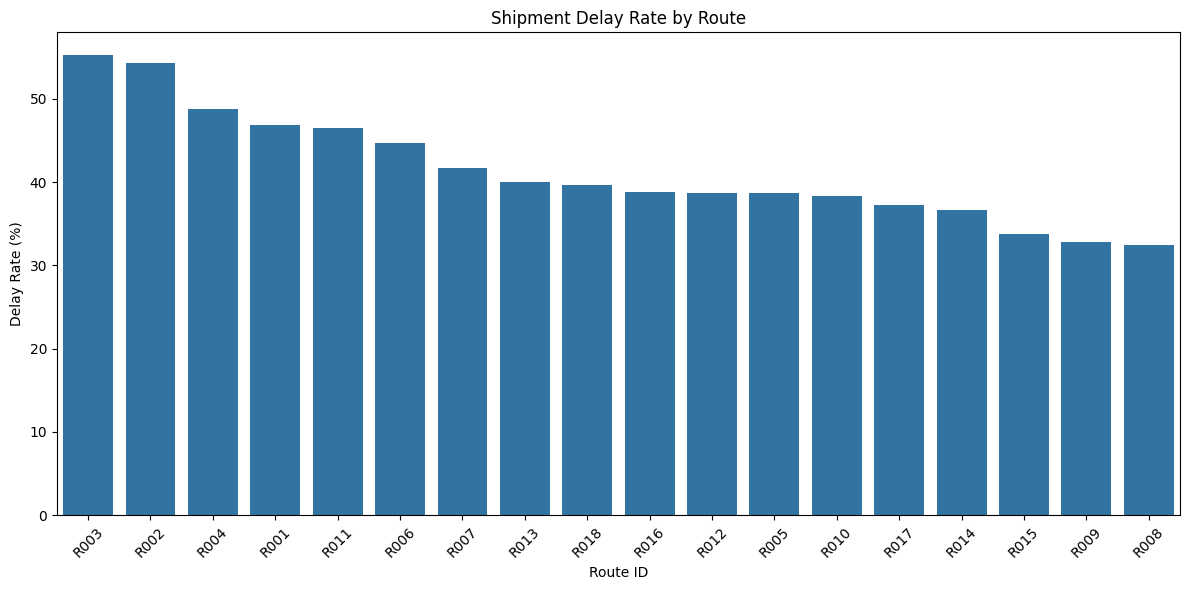

In [ ]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=route_analysis,
    x="route_id",
    y="delay_rate_percent"
)

plt.title("Shipment Delay Rate by Route")
plt.xlabel("Route ID")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

print("Top 5 routes by delay rate:")

display(
    route_analysis[
        ["route_id", "total_shipments", "delay_rate_percent", "avg_delay_days"]
    ].head(5).round(2)
)


Top 5 routes by delay rate:


,route_id,total_shipments,delay_rate_percent,avg_delay_days
2,R003,69,55.22,0.09
1,R002,72,54.29,0.15
3,R004,87,48.84,0.11
0,R001,49,46.81,-0.02
10,R011,59,46.55,0.02


Ques:2

In [ ]:
carrier_analysis = df.groupby("carrier").agg(
    total_shipments=("shipment_id", "count"),
    avg_transit_days=("transit_days", "mean"),
    avg_delay_days=("delay_days", "mean"),
    delayed_shipments=("is_delayed", "sum"),
    delay_rate=("is_delayed", "mean")
).reset_index()

carrier_analysis["delay_rate_percent"] = (
    carrier_analysis["delay_rate"] * 100
)

carrier_analysis = carrier_analysis.sort_values(
    "avg_transit_days",
    ascending=False
)

display(carrier_analysis.round(2))

,carrier,total_shipments,avg_transit_days,avg_delay_days,delayed_shipments,delay_rate,delay_rate_percent
3,TrackFast,288,2.35,0.05,128.0,0.45,45.39
1,GlobalMove,236,2.35,0.09,113.0,0.49,49.34
0,BlueDart,327,2.24,0.09,159.0,0.50,49.84
2,SwiftShip,349,2.12,-0.23,86.0,0.25,24.93


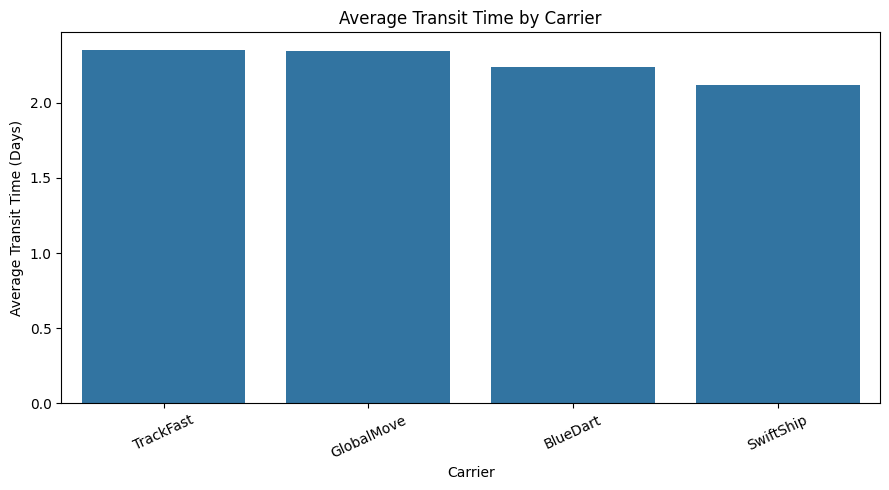

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=carrier_analysis,
    x="carrier",
    y="avg_transit_days"
)

plt.title("Average Transit Time by Carrier")
plt.xlabel("Carrier")
plt.ylabel("Average Transit Time (Days)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

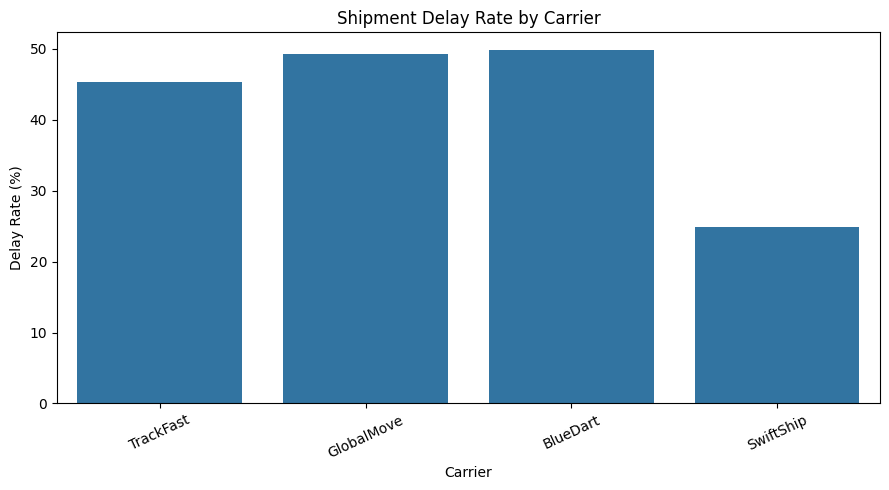

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=carrier_analysis,
    x="carrier",
    y="delay_rate_percent"
)

plt.title("Shipment Delay Rate by Carrier")
plt.xlabel("Carrier")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

Ques:3

In [ ]:

exception_analysis = df.groupby("has_exception").agg(
    total_shipments=("shipment_id", "count"),
    avg_delay_days=("delay_days", "mean"),
    delayed_shipments=("is_delayed", "sum"),
    delay_rate=("is_delayed", "mean"),
    avg_transit_days=("transit_days", "mean")
).reset_index()

exception_analysis["delay_rate_percent"] = (
    exception_analysis["delay_rate"] * 100
)

exception_analysis["exception_status"] = (
    exception_analysis["has_exception"]
    .map({0: "No recorded exception", 1: "Has recorded exception"})
)

display(exception_analysis.round(2))


,has_exception,total_shipments,avg_delay_days,delayed_shipments,delay_rate,avg_transit_days,delay_rate_percent,exception_status
0,0,875,-0.21,222.0,0.26,2.05,25.84,No recorded exception
1,1,325,0.53,264.0,0.84,2.79,83.54,Has recorded exception


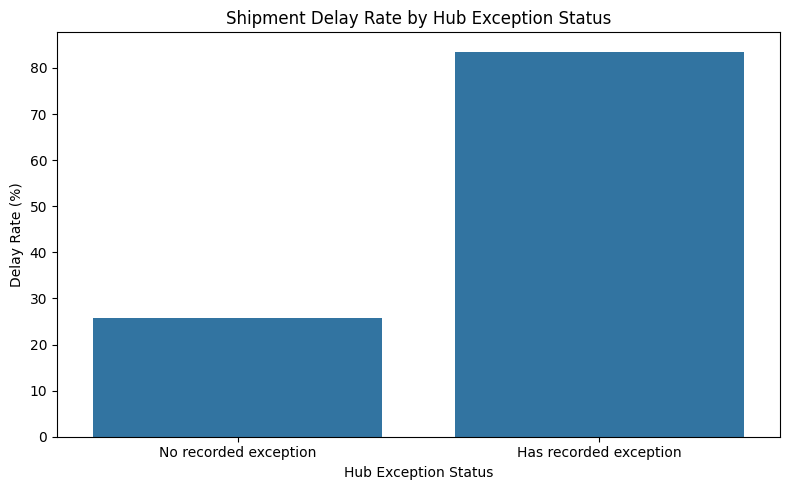

In [ ]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=exception_analysis,
    x="exception_status",
    y="delay_rate_percent"
)

plt.title("Shipment Delay Rate by Hub Exception Status")
plt.xlabel("Hub Exception Status")
plt.ylabel("Delay Rate (%)")
plt.tight_layout()
plt.show()


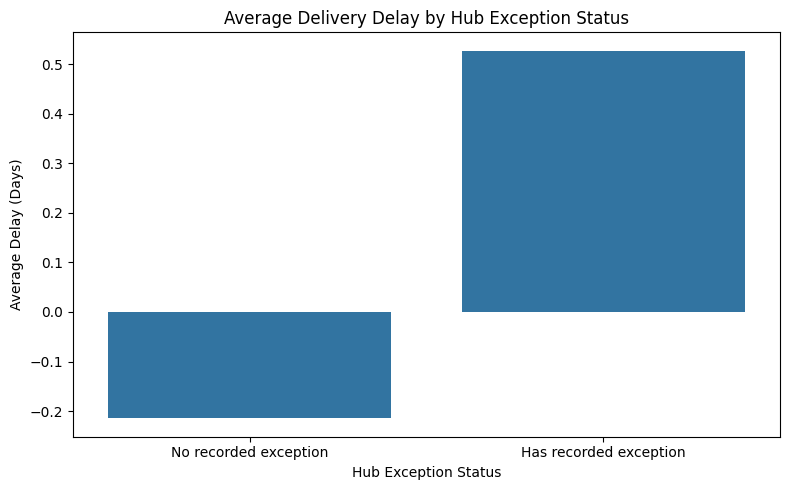

In [ ]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=exception_analysis,
    x="exception_status",
    y="avg_delay_days"
)

plt.title("Average Delivery Delay by Hub Exception Status")
plt.xlabel("Hub Exception Status")
plt.ylabel("Average Delay (Days)")
plt.tight_layout()
plt.show()


Ques:4

In [ ]:

weather_analysis = df.groupby("storm_flag").agg(
    total_shipments=("shipment_id", "count"),
    avg_delay_days=("delay_days", "mean"),
    delay_rate=("is_delayed", "mean"),
    avg_transit_days=("transit_days", "mean")
).reset_index()

weather_analysis["delay_rate_percent"] = (
    weather_analysis["delay_rate"] * 100
)

weather_analysis["storm_status"] = weather_analysis[
    "storm_flag"
].map({0: "No Storm", 1: "Storm"})

display(weather_analysis.round(2))


,storm_flag,total_shipments,avg_delay_days,delay_rate,avg_transit_days,delay_rate_percent,storm_status
0,0,1067,-0.08,0.37,2.18,36.56,No Storm
1,1,133,0.49,0.80,2.81,80.00,Storm


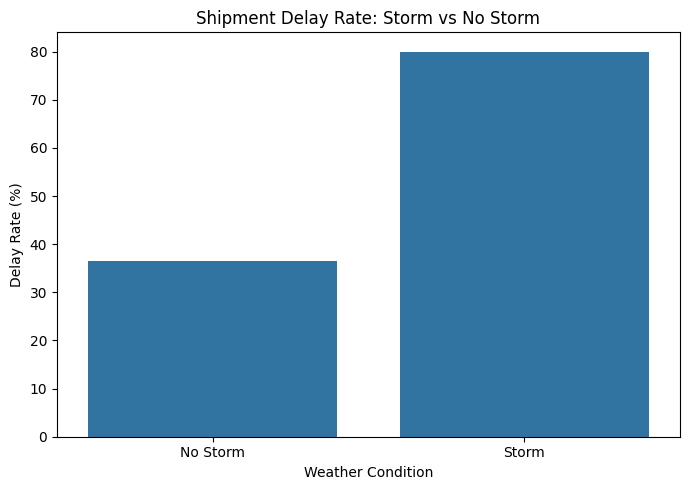

In [ ]:

plt.figure(figsize=(7, 5))

sns.barplot(
    data=weather_analysis,
    x="storm_status",
    y="delay_rate_percent"
)

plt.title("Shipment Delay Rate: Storm vs No Storm")
plt.xlabel("Weather Condition")
plt.ylabel("Delay Rate (%)")
plt.tight_layout()
plt.show()


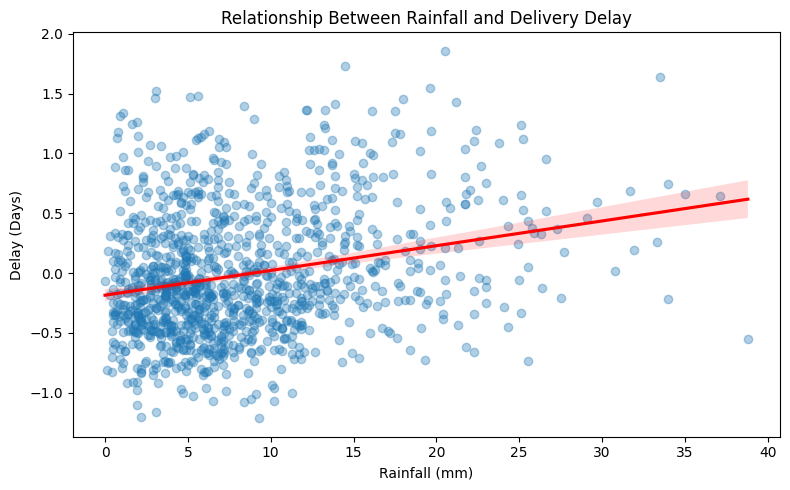

In [ ]:

plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x="rain_mm",
    y="delay_days",
    scatter_kws={"alpha": 0.35},
    line_kws={"color": "red"}
)

plt.title("Relationship Between Rainfall and Delivery Delay")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Delay (Days)")
plt.tight_layout()
plt.show()


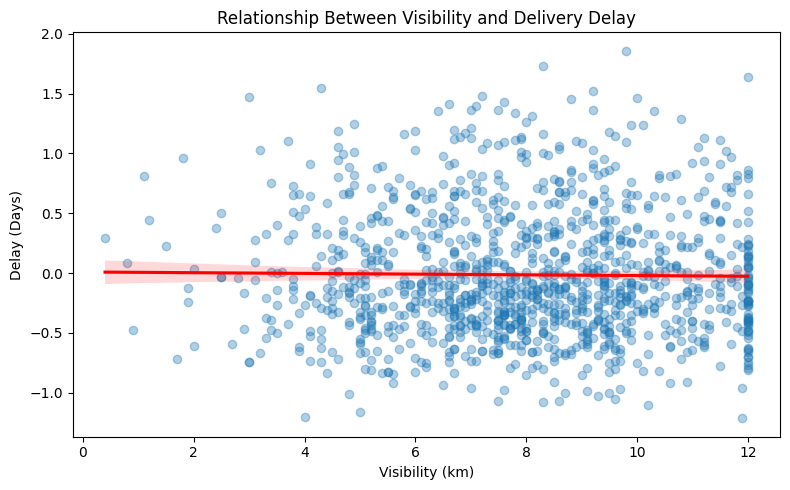

In [ ]:

plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x="visibility_km",
    y="delay_days",
    scatter_kws={"alpha": 0.35},
    line_kws={"color": "red"}
)

plt.title("Relationship Between Visibility and Delivery Delay")
plt.xlabel("Visibility (km)")
plt.ylabel("Delay (Days)")
plt.tight_layout()
plt.show()


Ques:5

In [ ]:

dispatch_analysis = df.groupby(
    "dispatch_period", observed=False
).agg(
    total_shipments=("shipment_id", "count"),
    avg_delay_days=("delay_days", "mean"),
    delay_rate=("is_delayed", "mean"),
    avg_transit_days=("transit_days", "mean")
).reset_index()

dispatch_analysis["delay_rate_percent"] = (
    dispatch_analysis["delay_rate"] * 100
)

display(dispatch_analysis.round(2))


,dispatch_period,total_shipments,avg_delay_days,delay_rate,avg_transit_days,delay_rate_percent
0,Night,302,-0.04,0.40,2.24,39.73
1,Morning,313,-0.06,0.38,2.17,37.79
2,Afternoon,286,0.01,0.44,2.34,44.13
3,Evening,299,0.03,0.44,2.26,44.14


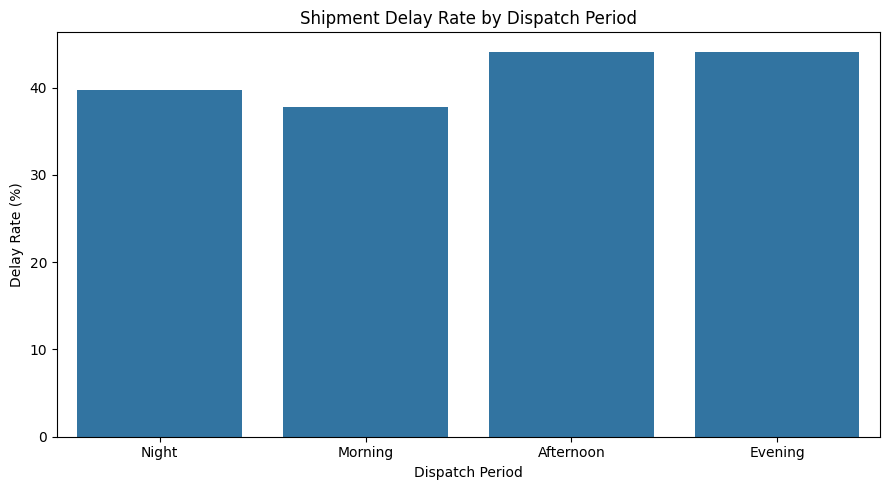

In [ ]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=dispatch_analysis,
    x="dispatch_period",
    y="delay_rate_percent"
)

plt.title("Shipment Delay Rate by Dispatch Period")
plt.xlabel("Dispatch Period")
plt.ylabel("Delay Rate (%)")
plt.tight_layout()
plt.show()


,dispatch_day,total_shipments,avg_delay_days,delay_rate,delay_rate_percent
0,Monday,190,-0.03,0.43,42.86
1,Tuesday,163,-0.03,0.43,43.40
2,Wednesday,165,-0.01,0.41,40.88
3,Thursday,181,-0.01,0.40,40.34
4,Friday,179,-0.04,0.37,37.29
5,Saturday,163,-0.01,0.39,38.61
6,Sunday,159,0.02,0.46,46.50


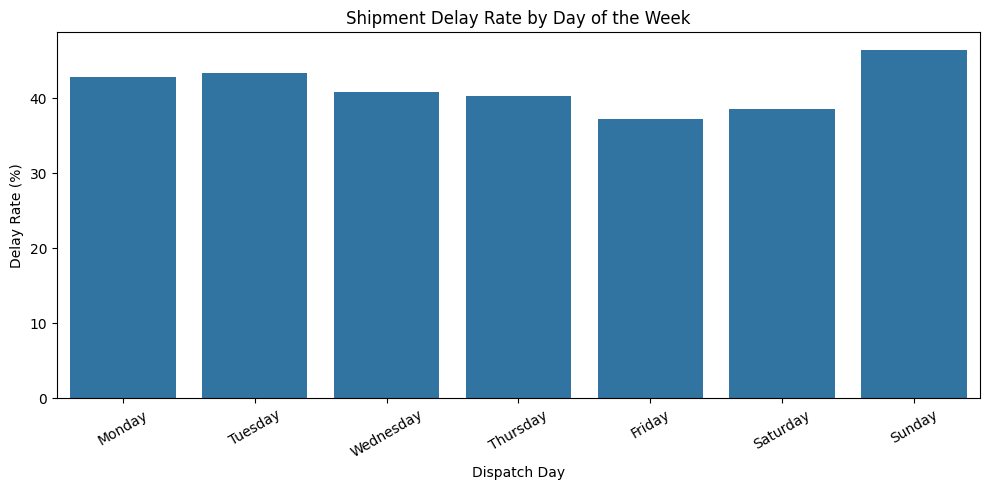

In [ ]:

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

day_analysis = df.groupby("dispatch_day").agg(
    total_shipments=("shipment_id", "count"),
    avg_delay_days=("delay_days", "mean"),
    delay_rate=("is_delayed", "mean")
).reindex(day_order).reset_index()

day_analysis["delay_rate_percent"] = (
    day_analysis["delay_rate"] * 100
)

display(day_analysis.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(
    data=day_analysis,
    x="dispatch_day",
    y="delay_rate_percent"
)

plt.title("Shipment Delay Rate by Day of the Week")
plt.xlabel("Dispatch Day")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


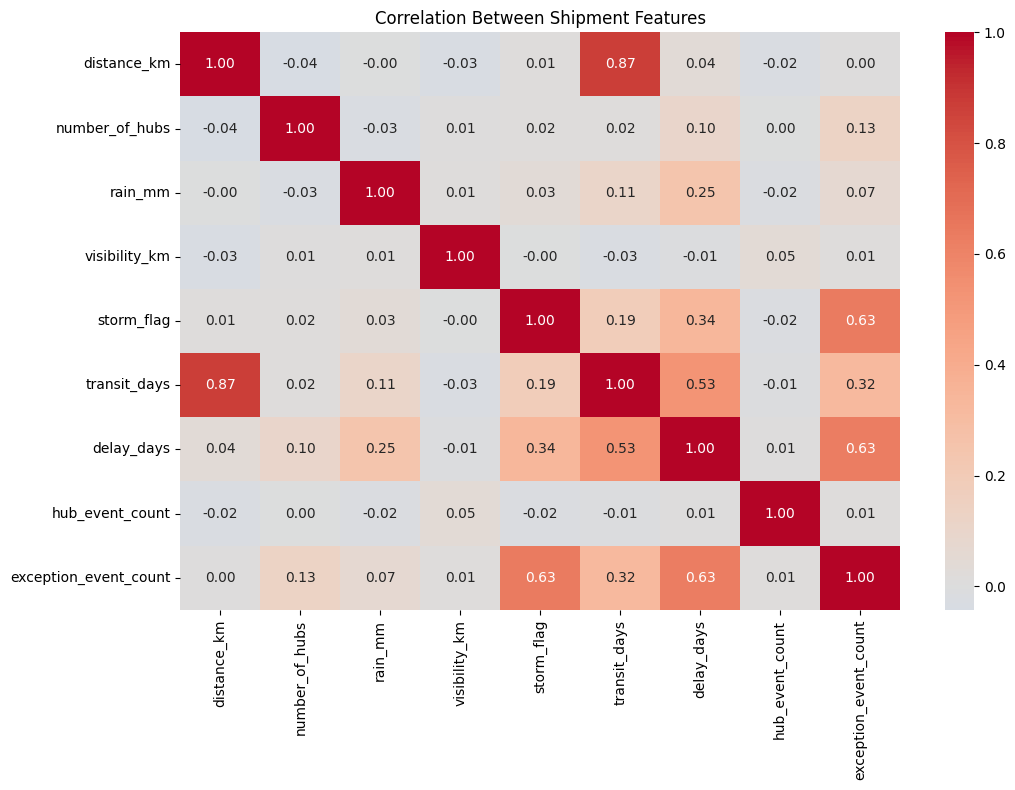

In [ ]:
numeric_cols = [
    "distance_km",
    "number_of_hubs",
    "rain_mm",
    "visibility_km",
    "storm_flag",
    "transit_days",
    "delay_days",
    "hub_event_count",
    "exception_event_count"
]

correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Between Shipment Features")
plt.tight_layout()
plt.show()


In [ ]:

print("===== FINAL DATA QUALITY REPORT =====")

print("\nDataset shape:", df.shape)
print("Unique shipment IDs:", df["shipment_id"].nunique())
print("Duplicate shipment IDs:",
      df["shipment_id"].duplicated().sum())

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nInvalid negative transit durations:",
      (df["transit_days"] < 0).sum())

print("\nDelay outcome counts:")
print(df["is_delayed"].value_counts(dropna=False))

print("\nDuplicate complete rows:", df.duplicated().sum())


===== FINAL DATA QUALITY REPORT =====

Dataset shape: (1200, 29)
Unique shipment IDs: 1200
Duplicate shipment IDs: 0

Missing values:
promised_delivery_date     6
actual_delivery_date      20
rain_mm                    5
transit_days              20
delay_days                25
is_delayed                25
dtype: int64

Invalid negative transit durations: 0

Delay outcome counts:
is_delayed
0.0    689
1.0    486
NaN     25
Name: count, dtype: int64

Duplicate complete rows: 0
